# Using Open Data with Python

Python is a multi-purpose programming language that can be used for web development, data analysis, mapping, and more.  Python has an extensive library of packages, with lots that can be used for data analysis.

This tutorial assumes users have some experience coding.  Below are the software requirments for this tutorial: 
- The user has an installation of Python on their computer. 
- The user has an Integrated Development Enviornment (IDE) installed, such as VSCode, or access to a cloud-based IDE, like Google Colab. 

## Libraries
To start, the libraries below are required to follow along with the tutorial. If you do not have these libraries installed use `pip install` in the terminal to install them. 

In [25]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

### Reading in the datasets
The datasets on the open data site are accessible through the ArcGIS Online API, which allows us to read in the data as a GeoJSON using the `requests` package.  Each dataset has an API link in the right hand corner of its page. For more information on using the API, there is a tutorial available at this link: [API Explorer Tutorial](https://data.syr.gov/pages/248865029e7c4fc3b98e1f8a4defe06b). There is also always the option to manually download the datasets in various formats.

In [37]:
unfit_link = "https://services6.arcgis.com/bdPqSfflsdgFRVVM/arcgis/rest/services/Unfit_Properties/FeatureServer/0/query?outFields=*&where=1%3D1&f=geojson"
unfit_json = requests.get(unfit_link).json()

neighborhoods_link = "https://services6.arcgis.com/bdPqSfflsdgFRVVM/arcgis/rest/services/Syracuse_Neighborhoods_20260604_view/FeatureServer/0/query?outFields=*&where=1%3D1&f=geojson"
neighborhoods_json = requests.get(neighborhoods_link).json()


### Normalize the JSON and simplify column names
Printing `unfit_json` displays the first thousand characters contained in the response, all of the data that we want is there but it's not in an easy to use format.  Through the pandas `json_normalize` function, the response will be flatten into a dataframe for easy use.

In [ ]:
print(unfit_json)

In [ ]:
unfit = pd.json_normalize(unfit_json["features"])
unfit.iloc[:, :6].head() 

# Note: This is only showing the first few columns and rows, since there are around 30 columns and 400 rows.
# Feel free to view more columns by just running unfit.head().

,type,id,geometry.type,geometry.coordinates,properties.complaint_number,properties.address
0,Feature,1,Point,"[-76.15663414, 43.0280662]",2026-06894,371 Kennedy St W
1,Feature,2,Point,"[-76.14261929, 43.0713786]",V2026-0512,1408 Butternut St
2,Feature,3,Point,"[-76.16254356, 43.03629779]",2026-06889,723 Onondaga St W
3,Feature,4,Point,"[-76.16254356, 43.03629779]",2026-06842,723 Onondaga St W
4,Feature,5,Point,"[-76.16254356, 43.03629779]",2025-04101,723 Onondaga St W


The response also adds `properties` and `geometry` to the begining of the column names that points to where in the data the column in coming from.  To avoid have to type longer column names out, the code below gets rid of the leading `properties` text. 

In [32]:
unfit.columns = unfit.columns.str.replace("properties.", "", regex=False)
unfit.iloc[:,:6].head()

,type,id,geometry.type,geometry.coordinates,complaint_number,address
0,Feature,1,Point,"[-76.15663414, 43.0280662]",2026-06894,371 Kennedy St W
1,Feature,2,Point,"[-76.14261929, 43.0713786]",V2026-0512,1408 Butternut St
2,Feature,3,Point,"[-76.16254356, 43.03629779]",2026-06889,723 Onondaga St W
3,Feature,4,Point,"[-76.16254356, 43.03629779]",2026-06842,723 Onondaga St W
4,Feature,5,Point,"[-76.16254356, 43.03629779]",2025-04101,723 Onondaga St W


### Reading in the neighborhoods data
Using the Geopandas `Geodataframe.from_features` function, the neighborhoods GeoJSON is being turned into a table with one row per neighborhood and a `geometry` column of polygon shapes that can be mapped and joined.

In [33]:
neighborhoods = gpd.GeoDataFrame.from_features(neighborhoods_json["features"], crs="EPSG:4326")
print(len(neighborhoods))

32


### Identifying what unfit properties are in each neighborhood's polygon
The next step is creating a points layer from the unfit properties dataset.  Following this, it is spatially joined to the neighborhoods dataset, based on if the unfit property point is in the neighborhood polygon or not.  From the neighborhoods layer, we are only keeping the `NAME` and `geometry` columns. 

In [34]:
unfit_points = gpd.GeoDataFrame(unfit, geometry=gpd.points_from_xy(unfit["Longitude"], unfit["Latitude"]), crs="EPSG:4326")
joined = gpd.sjoin(unfit_points, neighborhoods[["NAME", "geometry"]], how="left", predicate="within")
joined[["address", "NAME"]].head()

,address,NAME
0,371 Kennedy St W,Southside
1,1408 Butternut St,Northside
2,723 Onondaga St W,Southwest
3,723 Onondaga St W,Southwest
4,723 Onondaga St W,Southwest


### Getting counts per neighborhood
In order to map the number of unfit properties per neighborhood, the code below gets a count of each unique property that has been declared unfit,  The `counts` dataframe is then merged with the neighborhoods dataframe. 

In [35]:
counts = joined.groupby("NAME")["SBL"].nunique().rename("unfit_properties").reset_index()

merged = neighborhoods.merge(counts, on="NAME", how="left")
merged["unfit_properties"] = merged["unfit_properties"].fillna(0).astype(int)

merged[["NAME", "unfit_properties"]].sort_values("unfit_properties", ascending=False).head(10)

,NAME,unfit_properties
27,Northside,61
3,Brighton,26
29,Washington Square,26
14,Near Westside,25
11,Southwest,20
25,Lincoln Hill,19
9,Skunk City,19
4,Elmwood,19
28,Eastwood,18
20,Park Ave.,17


### Mapping
Finally, the code snippet below creates a simple map that shows the number of unfit properties per neighborhood using `matplotlib`.  

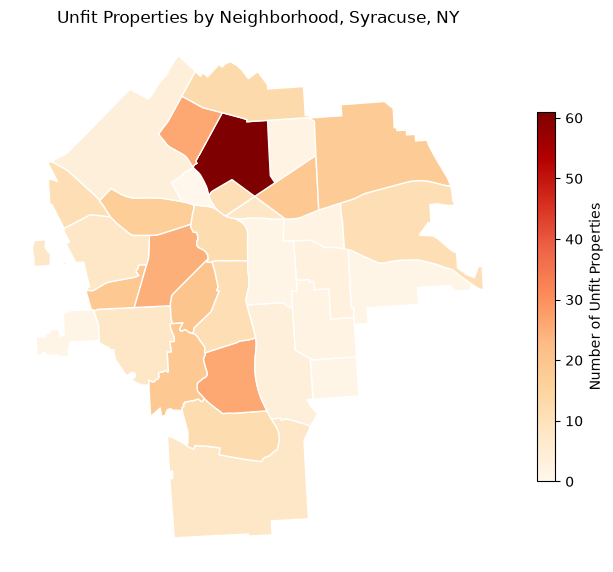

In [36]:
ax = merged.plot(column="unfit_properties", cmap="OrRd", edgecolor="white",
                 legend=True, legend_kwds={"label": "Number of Unfit Properties", "shrink": 0.6},
                 figsize=(8, 8))
ax.set_axis_off()
ax.set_title("Unfit Properties by Neighborhood, Syracuse, NY")
plt.show()

Thank you for using our tutorial. If you would like to see any other tutorials or datasets on the Syracuse Open Data site, please let us know at opendata@syr.gov! 